# Statistik Təhlil və Kəşfiyyat Xarakterli Məlumat Təhlili (EDA)

## Araşdırma 1: Bayram və Adi Günlərin Tranzaksiya Davranışına Təsiri

### Kitabxanaları import edek ve sql serverle elaqeni quraq

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src" / "db.py").exists():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("src/db.py tapılmadı")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.db import get_engine
from sqlalchemy import text
engine = get_engine()

print("SQL Server bağlantısı hazırdır!")

SQL Server bağlantısı hazırdır!


### Məlumatları SQL silver schemasından çağıraq

In [24]:
test_df = pd.read_sql("""
    SELECT TOP 5 *
    FROM silver.transactions
""", engine)

display(test_df)

,transaction_id,customer_id,date,time,amount,currency,category,channel,age,gender,city,branch,tenure_years,credit_score,balance,salary,products_count,has_card,is_active,churned,merge_date,is_holiday,holiday_name,is_weekend,is_workday,is_pre_holiday,rate_currency,rate_base,rate,temperature_2m_mean,precipitation_sum,wind_speed_10m_max
0,t0040264,c02529,2026-03-27,19:55:59,9.91,azn,alış-veriş,pos,34,qadın,bakı,nərimanov,3,707,706.36,513.59,1,1,1,0,2026-03-27,1,əlavə istirahət günü,0,0,0,None,None,None,10.9,35.5,25.1
1,t0040265,c04195,2026-03-27,19:56:53,794.63,azn,nağdlaşdırma,atm,45,qadın,bakı,xətai,10,536,18968.19,2414.68,2,1,1,0,2026-03-27,1,əlavə istirahət günü,0,0,0,None,None,None,10.9,35.5,25.1
2,t0040266,c03812,2026-03-27,19:57:15,120.90,azn,köçürmə,mobil tətbiq,40,qadın,bakı,binəqədi,10,670,19961.35,1229.66,1,1,1,1,2026-03-27,1,əlavə istirahət günü,0,0,0,None,None,None,10.9,35.5,25.1
3,t0040267,c00782,2026-03-27,19:57:17,13.81,azn,alış-veriş,pos,48,qadın,naxçıvan,naxçıvan mərkəz,4,685,14354.76,589.29,1,1,1,0,2026-03-27,1,əlavə istirahət günü,0,0,0,None,None,None,10.0,14.3,13.8
4,t0040268,c02866,2026-03-27,19:57:21,36.76,azn,alış-veriş,pos,41,qadın,lənkəran,lənkəran mərkəz,5,661,9151.89,1662.48,3,1,1,0,2026-03-27,1,əlavə istirahət günü,0,0,0,None,None,None,13.1,14.3,11.0


### tarix üzrə tranzaksiya sayı və məbləğini araşdıraq

In [42]:
daily_df = pd.read_sql("""
    SELECT
        CAST(date AS DATE) AS tarix,

        MAX(is_holiday) AS bayram_gunu,

        COUNT(transaction_id) AS tranzaksiya_sayi,

        SUM(
            CASE
                WHEN currency = 'azn' THEN amount
                WHEN currency IN ('usd', 'eur')
                     AND rate > 0
                     AND rate_base = 'azn'
                     AND rate_currency = currency
                THEN amount / rate
                ELSE NULL
            END
        ) AS umumi_mebleg

    FROM silver.transactions

    WHERE date IS NOT NULL
      AND amount IS NOT NULL

    GROUP BY CAST(date AS DATE)

    ORDER BY tarix
""", engine)

daily_df["tarix"] = pd.to_datetime(daily_df["tarix"])

display(daily_df.head(10))

,tarix,bayram_gunu,tranzaksiya_sayi,umumi_mebleg
0,2026-01-01,1,623,43359.991432
1,2026-01-02,1,750,55605.069187
2,2026-01-03,0,322,28117.890687
3,2026-01-04,0,226,15942.634611
4,2026-01-05,0,722,82965.803090
5,2026-01-06,0,510,48403.787164
6,2026-01-07,0,475,52201.430324
7,2026-01-08,0,462,41313.529298
8,2026-01-09,0,535,49706.594124
9,2026-01-10,0,333,27064.467203


### Gündəlik məlumatların yoxlanması

In [38]:
print("Dataset ölçüsü:", daily_df.shape)

print("\nBoş dəyərlər:")
print(daily_df.isnull().sum())

print("\nBayram və adi günlərin sayı:")
print(daily_df["bayram_gunu"].value_counts())

print("\nTəkrarlanan tarixlər:")
print(daily_df["tarix"].duplicated().sum())

Dataset ölçüsü: (181, 4)

Boş dəyərlər:
tarix               0
bayram_gunu         0
tranzaksiya_sayi    0
umumi_mebleg        0
dtype: int64

Bayram və adi günlərin sayı:
bayram_gunu
0    160
1     21
Name: count, dtype: int64

Təkrarlanan tarixlər:
0


### Dataset 181 günlük məlumatdan ibarətdir: 160 adi gün və 21 bayram günü. Boş dəyərlər və təkrarlanan tarixlər aşkar edilmədi. Məlumatlar statistik müqayisə üçün ilkin olaraq uyğundur.

In [39]:
summary_df = daily_df.groupby("bayram_gunu").agg(
    gun_sayi=("tarix", "count"),
    orta_tranzaksiya_sayi=("tranzaksiya_sayi", "mean"),
    median_tranzaksiya_sayi=("tranzaksiya_sayi", "median"),
    orta_gunluk_mebleg=("umumi_mebleg", "mean"),
    median_gunluk_mebleg=("umumi_mebleg", "median")
).round(2)

display(summary_df)

# Bayram günlərinin adi günlərlə faiz fərqi
say_faizi = (
    summary_df.loc[1, "orta_tranzaksiya_sayi"] /
    summary_df.loc[0, "orta_tranzaksiya_sayi"] - 1
) * 100

mebleg_faizi = (
    summary_df.loc[1, "orta_gunluk_mebleg"] /
    summary_df.loc[0, "orta_gunluk_mebleg"] - 1
) * 100

print(f"\nTranzaksiya sayı fərqi: {say_faizi:+.2f}%")
print(f"Tranzaksiya məbləği fərqi: {mebleg_faizi:+.2f}%")

,gun_sayi,orta_tranzaksiya_sayi,median_tranzaksiya_sayi,orta_gunluk_mebleg,median_gunluk_mebleg
bayram_gunu,,,,,
0,160,425.09,422.0,39713.06,39441.93
1,21,446.76,437.0,31892.35,31351.54



Tranzaksiya sayı fərqi: +5.10%
Tranzaksiya məbləği fərqi: -19.69%


### Qrafiklə müqayisə

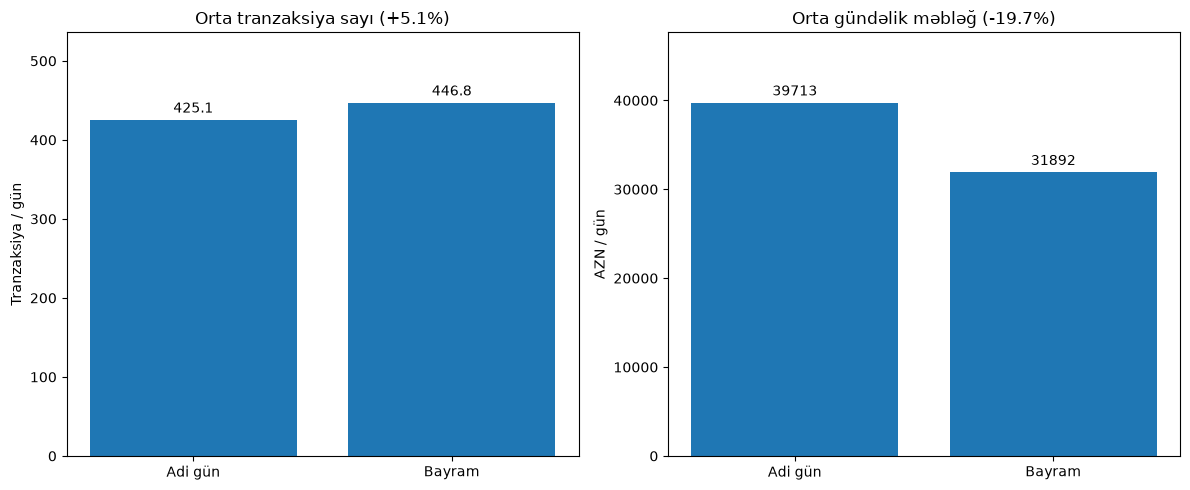

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Orta tranzaksiya sayı
say = summary_df["orta_tranzaksiya_sayi"]

axes[0].bar(["Adi gün", "Bayram"], say)
axes[0].bar_label(axes[0].containers[0], fmt="%.1f", padding=3)
axes[0].set_title(f"Orta tranzaksiya sayı ({say_faizi:+.1f}%)")
axes[0].set_ylabel("Tranzaksiya / gün")
axes[0].set_ylim(0, say.max() * 1.2)

# Orta gündəlik məbləğ
mebleg = summary_df["orta_gunluk_mebleg"]

axes[1].bar(["Adi gün", "Bayram"], mebleg)
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3)
axes[1].set_title(f"Orta gündəlik məbləğ ({mebleg_faizi:+.1f}%)")
axes[1].set_ylabel("AZN / gün")
axes[1].set_ylim(0, mebleg.max() * 1.2)

plt.tight_layout()
plt.show()

### Bayram günlərində orta gündəlik tranzaksiya sayı 5.1% artır, ümumi tranzaksiya məbləği isə 19.7% azalır. Bu nəticə bayram günlərində daha çox, lakin nisbətən kiçik məbləğli əməliyyatların aparıldığını göstərən ilkin müşahidədir.

### Outlier Analiz - 
#### Gündəlik tranzaksiya sayı və məbləğində kənar dəyərlər IQR metodu ilə müəyyən edilir. Outlier-lərin orta göstəricilərə təsiri ayrıca yoxlanılır.

In [43]:
for sutun in ["tranzaksiya_sayi", "umumi_mebleg"]:

    print("\n", sutun)

    for qrup in [0, 1]:
        data = daily_df[daily_df["bayram_gunu"] == qrup][sutun]

        Q1 = data.quantile(0.25)
        Q3 = data.quantile(0.75)
        IQR = Q3 - Q1

        temiz = data[
            (data >= Q1 - 1.5 * IQR) &
            (data <= Q3 + 1.5 * IQR)
        ]

        print(
            "Bayram" if qrup == 1 else "Adi gün",
            "| Outlier:", len(data) - len(temiz),
            "| Əvvəl:", round(data.mean(), 2),
            "| Sonra:", round(temiz.mean(), 2)
        )


 tranzaksiya_sayi
Adi gün | Outlier: 4 | Əvvəl: 425.09 | Sonra: 416.66
Bayram | Outlier: 0 | Əvvəl: 446.76 | Sonra: 446.76

 umumi_mebleg
Adi gün | Outlier: 2 | Əvvəl: 39713.06 | Sonra: 39165.03
Bayram | Outlier: 1 | Əvvəl: 31892.35 | Sonra: 30706.71


### Boxplot qrafiki

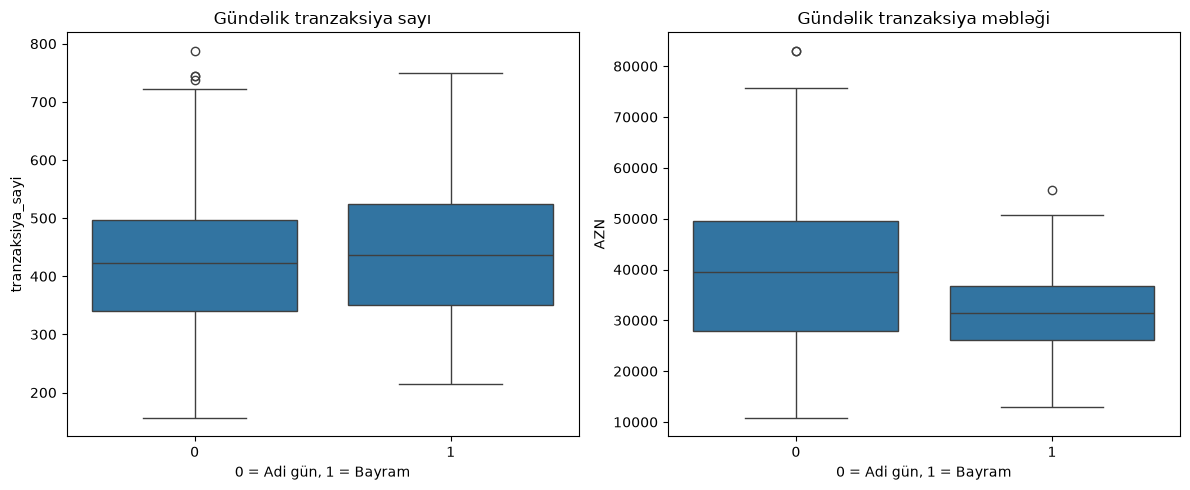

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=daily_df, x="bayram_gunu",
            y="tranzaksiya_sayi", ax=axes[0])

axes[0].set_title("Gündəlik tranzaksiya sayı")
axes[0].set_xlabel("0 = Adi gün, 1 = Bayram")

sns.boxplot(data=daily_df, x="bayram_gunu",
            y="umumi_mebleg", ax=axes[1])

axes[1].set_title("Gündəlik tranzaksiya məbləği")
axes[1].set_xlabel("0 = Adi gün, 1 = Bayram")
axes[1].set_ylabel("AZN")

plt.tight_layout()
plt.show()

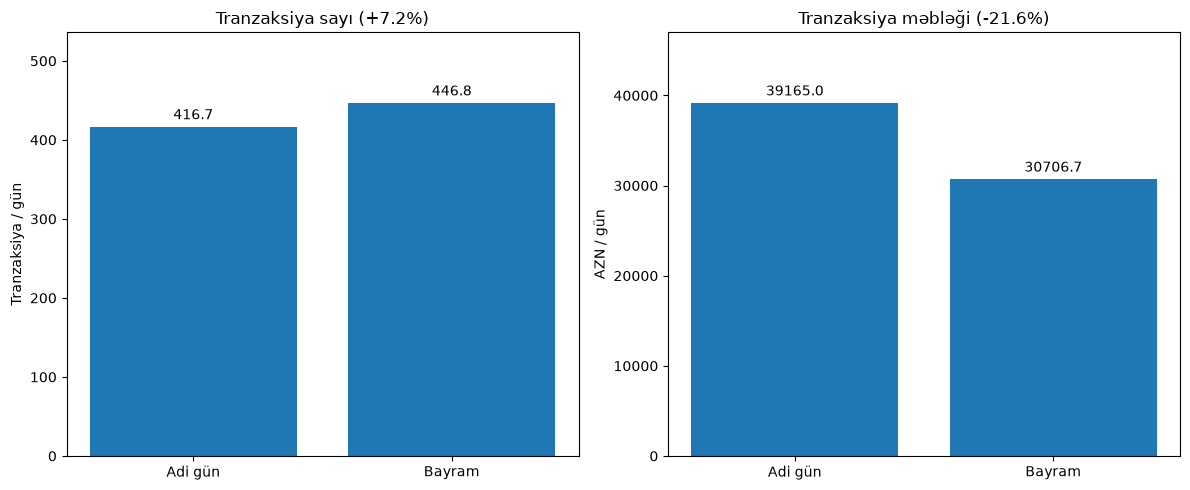

In [45]:
# Outlier-siz ortalamaları hesablayırıq
neticeler = []

for sutun in ["tranzaksiya_sayi", "umumi_mebleg"]:
    ortalar = []

    for qrup in [0, 1]:
        data = daily_df[daily_df["bayram_gunu"] == qrup][sutun]

        Q1 = data.quantile(0.25)
        Q3 = data.quantile(0.75)
        IQR = Q3 - Q1

        temiz = data[
            (data >= Q1 - 1.5 * IQR) &
            (data <= Q3 + 1.5 * IQR)
        ]

        ortalar.append(temiz.mean())

    neticeler.append(ortalar)

# Qrafiklər
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, (ortalar, basliq) in enumerate(zip(
    neticeler, ["Tranzaksiya sayı", "Tranzaksiya məbləği"]
)):
    faiz = (ortalar[1] / ortalar[0] - 1) * 100

    axes[i].bar(["Adi gün", "Bayram"], ortalar)
    axes[i].bar_label(axes[i].containers[0], fmt="%.1f", padding=3)
    axes[i].set_title(f"{basliq} ({faiz:+.1f}%)")
    axes[i].set_ylim(0, max(ortalar) * 1.2)

axes[0].set_ylabel("Tranzaksiya / gün")
axes[1].set_ylabel("AZN / gün")

plt.tight_layout()
plt.show()

#### Tranzaksiya sayında adi günlər üzrə 4 outlier, bayram günlərində isə 0 outlier aşkar edildi.

#### Tranzaksiya məbləğində adi günlər üzrə 2, bayram günlərində isə 1 outlier müəyyən edildi.

#### Outlier-lər nəzərə alınmadıqda bayram günlərində orta gündəlik tranzaksiya sayı adi günlərdən 7.2% yüksək, ümumi tranzaksiya məbləği isə 21.6% aşağıdır.orta göstəricilər bir qədər dəyişsə də, əsas nəticə dəyişmir: bayram günlərində tranzaksiya sayı daha yüksək, ümumi məbləğ isə daha aşağıdır.

#### Outlier-lər real bank əməliyyatları ola biləcəyi üçün əsas datasetdən silinmədi.

### Hipotez testi
#### Bu mərhələdə bayram və adi günlərdə tranzaksiya sayı və məbləği arasında müşahidə etdiyimiz fərqlərin statistik baxımdan əhəmiyyətli olub-olmadığını yoxlayacağıq.

##### H₀ — Sıfır hipotezi: Bayram və adi günlərdə orta gündəlik tranzaksiya göstəriciləri arasında fərq yoxdur.

##### H₁ — Alternativ hipotez: Bayram və adi günlərdə orta gündəlik tranzaksiya göstəriciləri arasında fərq var.

##### Bu hipotezləri tranzaksiya sayı və məbləği üçün ayrı-ayrılıqda yoxlayacağıq.

##### Welch's t-test seçirik Çünki İki müstəqil qrupu müqayisə edirik: 160 adi gün və 21 bayram günü. Qruplardakı günlərin sayı fərqlidir.Test iki qrupun orta göstəricilərini müqayisə edir

In [46]:
from scipy import stats

adi = daily_df[daily_df["bayram_gunu"] == 0]
bayram = daily_df[daily_df["bayram_gunu"] == 1]

for sutun in ["tranzaksiya_sayi", "umumi_mebleg"]:

    t, p = stats.ttest_ind(
        adi[sutun],
        bayram[sutun],
        equal_var=False
    )

    print("Göstərici:", sutun)
    print("T-statistika:", round(t, 3))
    print("P-dəyəri:", round(p, 4))
    print()


Göstərici: tranzaksiya_sayi
T-statistika: -0.655
P-dəyəri: 0.5182

Göstərici: umumi_mebleg
T-statistika: 3.02
P-dəyəri: 0.0048



#### Tranzaksiya sayı: P-dəyəri 0.5182 olduğu üçün bayram və adi günlər arasında statistik əhəmiyyətli fərq aşkar edilmədi.

#### Tranzaksiya məbləği: P-dəyəri 0.0048 olduğu üçün bayram və adi günlər arasında statistik əhəmiyyətli fərq aşkar edildi. Bayram günlərində orta gündəlik tranzaksiya məbləği adi günlərdən 19.7% aşağıdır.

#### Yekun nəticə: İlkin statistik testə əsasən, bayram günləri tranzaksiya sayında əhəmiyyətli dəyişiklik müşahidə olunmur, lakin gündəlik tranzaksiya məbləğində əhəmiyyətli azalma var.

## Maaş günlərinin təsiri
#### Ayın 1–5-də gündəlik tranzaksiya sayı və məbləği digər günlərdən fərqlənirmi?

In [47]:
# Maaş günlərini müəyyən edirik
daily_df["tarix"] = pd.to_datetime(daily_df["tarix"])

daily_df["maas_gunu"] = (
    daily_df["tarix"].dt.day <= 5
).astype(int)

# Orta göstəriciləri hesablayırıq
maas_df = daily_df.groupby("maas_gunu").agg(
    gun_sayi=("tarix", "count"),
    orta_tranzaksiya_sayi=("tranzaksiya_sayi", "mean"),
    orta_gunluk_mebleg=("umumi_mebleg", "mean")
).round(2)

display(maas_df)

# Faiz fərqləri
say_faizi = (
    maas_df.loc[1, "orta_tranzaksiya_sayi"] /
    maas_df.loc[0, "orta_tranzaksiya_sayi"] - 1
) * 100

mebleg_faizi = (
    maas_df.loc[1, "orta_gunluk_mebleg"] /
    maas_df.loc[0, "orta_gunluk_mebleg"] - 1
) * 100

print(f"Tranzaksiya sayı fərqi: {say_faizi:+.2f}%")
print(f"Tranzaksiya məbləği fərqi: {mebleg_faizi:+.2f}%")

,gun_sayi,orta_tranzaksiya_sayi,orta_gunluk_mebleg
maas_gunu,,,
0,151,411.86,37163.09
1,30,506.83,47073.42


Tranzaksiya sayı fərqi: +23.06%
Tranzaksiya məbləği fərqi: +26.67%


### Maaş dövrünün qrafiklə müqayisəsi

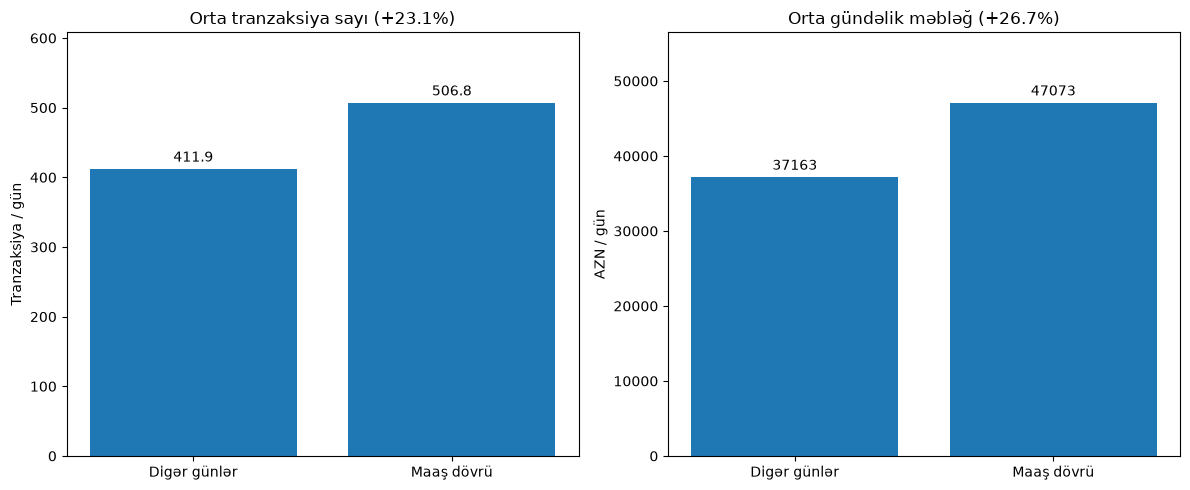

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

adlar = ["Digər günlər", "Maaş dövrü"]

say = maas_df["orta_tranzaksiya_sayi"]
axes[0].bar(adlar, say)
axes[0].bar_label(axes[0].containers[0], fmt="%.1f", padding=3)
axes[0].set_title(f"Orta tranzaksiya sayı ({say_faizi:+.1f}%)")
axes[0].set_ylabel("Tranzaksiya / gün")
axes[0].set_ylim(0, say.max() * 1.2)

mebleg = maas_df["orta_gunluk_mebleg"]
axes[1].bar(adlar, mebleg)
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3)
axes[1].set_title(f"Orta gündəlik məbləğ ({mebleg_faizi:+.1f}%)")
axes[1].set_ylabel("AZN / gün")
axes[1].set_ylim(0, mebleg.max() * 1.2)

plt.tight_layout()
plt.show()

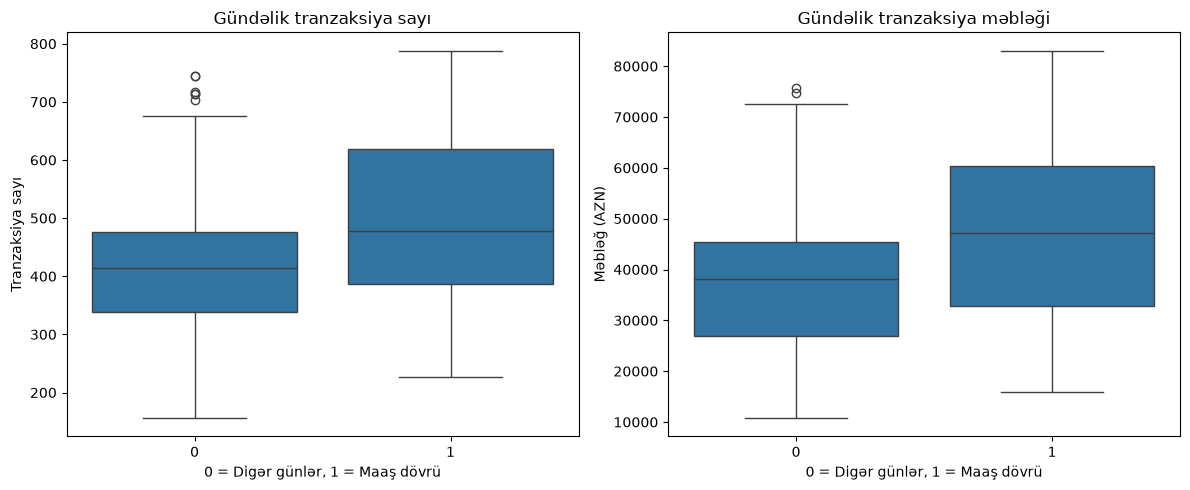

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=daily_df,
    x="maas_gunu",
    y="tranzaksiya_sayi",
    ax=axes[0]
)

axes[0].set_title("Gündəlik tranzaksiya sayı")
axes[0].set_xlabel("0 = Digər günlər, 1 = Maaş dövrü")
axes[0].set_ylabel("Tranzaksiya sayı")

sns.boxplot(
    data=daily_df,
    x="maas_gunu",
    y="umumi_mebleg",
    ax=axes[1]
)

axes[1].set_title("Gündəlik tranzaksiya məbləği")
axes[1].set_xlabel("0 = Digər günlər, 1 = Maaş dövrü")
axes[1].set_ylabel("Məbləğ (AZN)")

plt.tight_layout()
plt.show()

#### Sol qrafik — Tranzaksiya sayı
- Maaş dövründə (1) median tranzaksiya sayı digər günlərdən (0) yüksəkdir.
- Digər günlərdə bir neçə outlier görünür.
- Maaş dövründə isə boxplot qaydasına görə outlier görünmür.
#### Sağ qrafik — Tranzaksiya məbləği
- Maaş dövründə median gündəlik məbləğ daha yüksəkdir.
- Digər günlərdə yüksək məbləğli bir neçə outlier var.
- Maaş dövründə outlier görünmür, amma gündəlik məbləğlər daha geniş aralıqda dəyişir.

### Maaş dövründə outlier-lərin təsiri

In [50]:
neticeler = []

for sutun in ["tranzaksiya_sayi", "umumi_mebleg"]:
    ortalar = []

    print("\n", sutun)

    for qrup in [0, 1]:
        data = daily_df[daily_df["maas_gunu"] == qrup][sutun]

        q1 = data.quantile(0.25)
        q3 = data.quantile(0.75)
        iqr = q3 - q1

        temiz = data[
            (data >= q1 - 1.5 * iqr) &
            (data <= q3 + 1.5 * iqr)
        ]

        ortalar.append(temiz.mean())

        print(
            "Maaş dövrü" if qrup == 1 else "Digər günlər",
            "| Outlier:", len(data) - len(temiz),
            "| Əvvəl:", round(data.mean(), 2),
            "| Sonra:", round(temiz.mean(), 2)
        )

    neticeler.append(ortalar)


 tranzaksiya_sayi
Digər günlər | Outlier: 6 | Əvvəl: 411.86 | Sonra: 398.99
Maaş dövrü | Outlier: 0 | Əvvəl: 506.83 | Sonra: 506.83

 umumi_mebleg
Digər günlər | Outlier: 2 | Əvvəl: 37163.09 | Sonra: 36651.6
Maaş dövrü | Outlier: 0 | Əvvəl: 47073.42 | Sonra: 47073.42


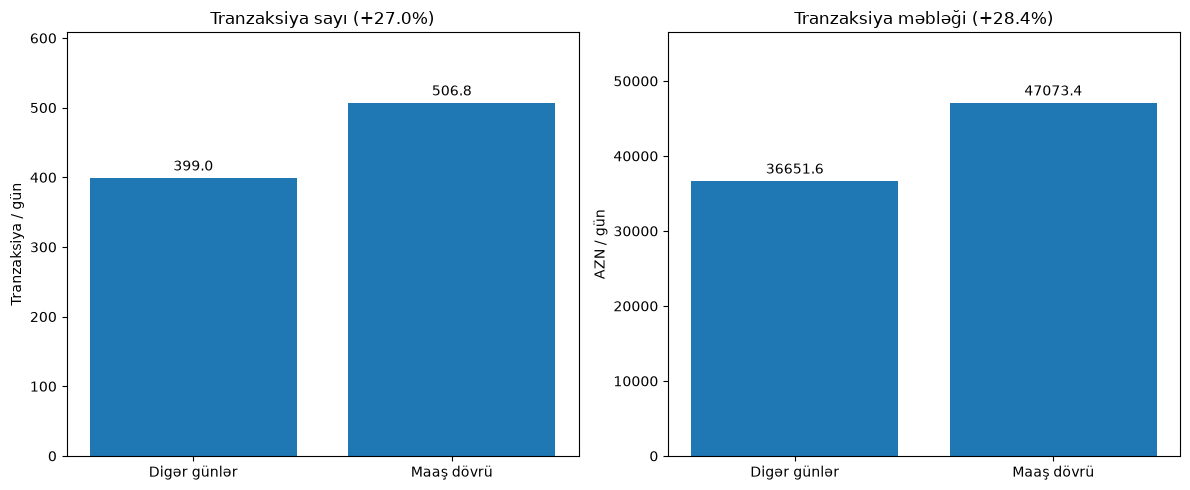

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

basliqlar = ["Tranzaksiya sayı", "Tranzaksiya məbləği"]

for i in range(2):
    ortalar = neticeler[i]
    faiz = (ortalar[1] / ortalar[0] - 1) * 100

    axes[i].bar(["Digər günlər", "Maaş dövrü"], ortalar)
    axes[i].bar_label(axes[i].containers[0], fmt="%.1f", padding=3)
    axes[i].set_title(f"{basliqlar[i]} ({faiz:+.1f}%)")
    axes[i].set_ylim(0, max(ortalar) * 1.2)

axes[0].set_ylabel("Tranzaksiya / gün")
axes[1].set_ylabel("AZN / gün")

plt.tight_layout()
plt.show()

#### Outlier-lər çıxarıldıqdan sonra maaş dövründə orta gündəlik tranzaksiya sayı digər günlərdən 27.0%, tranzaksiya məbləği isə 28.4% yüksəkdir.

#### Əvvəlki nəticələrlə müqayisədə fərqlər bir qədər artsa da, əsas müşahidə dəyişmir: maaş dövründə tranzaksiya aktivliyi daha yüksəkdir.

### Maaş dövrü üzrə hipotez testi

#### H₀ — Sıfır hipotezi: Maaş dövrü ilə digər günlər arasında orta gündəlik tranzaksiya göstəriciləri baxımından fərq yoxdur.

#### H₁ — Alternativ hipotez: Maaş dövrü ilə digər günlər arasında orta gündəlik tranzaksiya göstəriciləri baxımından fərq var.

#### Welch's t-test seçirik Çünki İki müstəqil qrupu müqayisə edirik  30 maaş dövrü günü və 151 digər gün.Qrupların ölçüləri fərqlidir. Bu test qrupların dəyişkənliyinin eyni olmasını tələb etmir.

In [52]:
from scipy import stats

adi = daily_df[daily_df["maas_gunu"] == 0]
maas = daily_df[daily_df["maas_gunu"] == 1]

for sutun in ["tranzaksiya_sayi", "umumi_mebleg"]:

    t, p = stats.ttest_ind(
        adi[sutun],
        maas[sutun],
        equal_var=False
    )

    print("Göstərici:", sutun)
    print("T-statistika:", round(t, 3))
    print("P-dəyəri:", round(p, 4))

    if p < 0.05:
        print("Nəticə: Statistik əhəmiyyətli fərq var.")
    else:
        print("Nəticə: Statistik əhəmiyyətli fərq aşkar edilmədi.")

    print()

Göstərici: tranzaksiya_sayi
T-statistika: -2.982
P-dəyəri: 0.0051
Nəticə: Statistik əhəmiyyətli fərq var.

Göstərici: umumi_mebleg
T-statistika: -2.716
P-dəyəri: 0.0101
Nəticə: Statistik əhəmiyyətli fərq var.



#### Maaş dövrü ilə digər günlər arasında həm gündəlik tranzaksiya sayı (p = 0.0051), həm də tranzaksiya məbləği (p = 0.0101) üzrə statistik əhəmiyyətli fərq aşkar edilmişdir. Şərti maaş dövründə (ayın 1–5-i) orta gündəlik tranzaksiya sayı 23.06%, mməbləği isə 26.67% yüksəkdir.

## Məzənnənin tranzaksiya davranışı ilə əlaqəsinin araşdırılması
#### Bayram və maaş dövrü analizlərini tamamladıq. İndi USD və EUR məzənnələrinin dəyişməsi ilə müştərilərin tranzaksiya aktivliyi arasında əlaqə olub-olmadığını araşdıracağıq.

In [53]:
fx_df = pd.read_sql_table("transactions", engine, schema="silver")

#### USD və EUR üzrə gündəlik məzənnəni, tranzaksiya sayını və məbləğini hazırlayaq

In [54]:
fx_df = fx_df[fx_df["currency"].isin(["usd", "eur"])].copy()

fx_df["date"] = pd.to_datetime(fx_df["date"])

exchange_df = fx_df.groupby(
    [fx_df["date"].dt.date, "currency"]
).agg(
    mezenne=("rate", "first"),
    tranzaksiya_sayi=("transaction_id", "count"),
    umumi_mebleg=("amount", "sum")
).reset_index()

display(exchange_df.head(10))

,date,currency,mezenne,tranzaksiya_sayi,umumi_mebleg
0,2026-01-01,eur,0.50084,17,599.34
1,2026-01-01,usd,0.58837,30,1395.55
2,2026-01-02,eur,0.50095,30,1090.59
3,2026-01-02,usd,0.58830,25,761.74
4,2026-01-03,eur,0.50107,5,196.17
5,2026-01-03,usd,0.58837,11,628.19
6,2026-01-04,eur,0.50114,7,360.51
7,2026-01-04,usd,0.58838,11,622.35
8,2026-01-05,eur,0.50266,22,2446.37
9,2026-01-05,usd,0.58812,32,2594.70


### Analizə başlamazdan əvvəl boş dəyərləri, təkrarlanan tarix-valyuta cütlərini və bir gündə fərqli məzənnələrin olub-olmadığını yoxlayaq.

In [55]:
print("Sətir sayı:", len(exchange_df))

print("\nBoş dəyərlər:")
print(exchange_df.isnull().sum())

print("\nTəkrarlanan tarix-valyuta:")
print(exchange_df.duplicated(["date", "currency"]).sum())

print("\nEyni gündə fərqli məzənnə olan hallar:")
print(
    fx_df.groupby(["date", "currency"])["rate"]
    .nunique()
    .gt(1)
    .sum()
)

Sətir sayı: 362

Boş dəyərlər:
date                0
currency            0
mezenne             0
tranzaksiya_sayi    0
umumi_mebleg        0
dtype: int64

Təkrarlanan tarix-valyuta:
0

Eyni gündə fərqli məzənnə olan hallar:
0


##### Məlumatlarda boş dəyərlər, təkrarlanan tarix-valyuta cütləri və eyni gündə fərqli məzənnələr aşkar edilməmişdir.

### USD və EUR məzənnələrinin zaman üzrə dəyişməsi

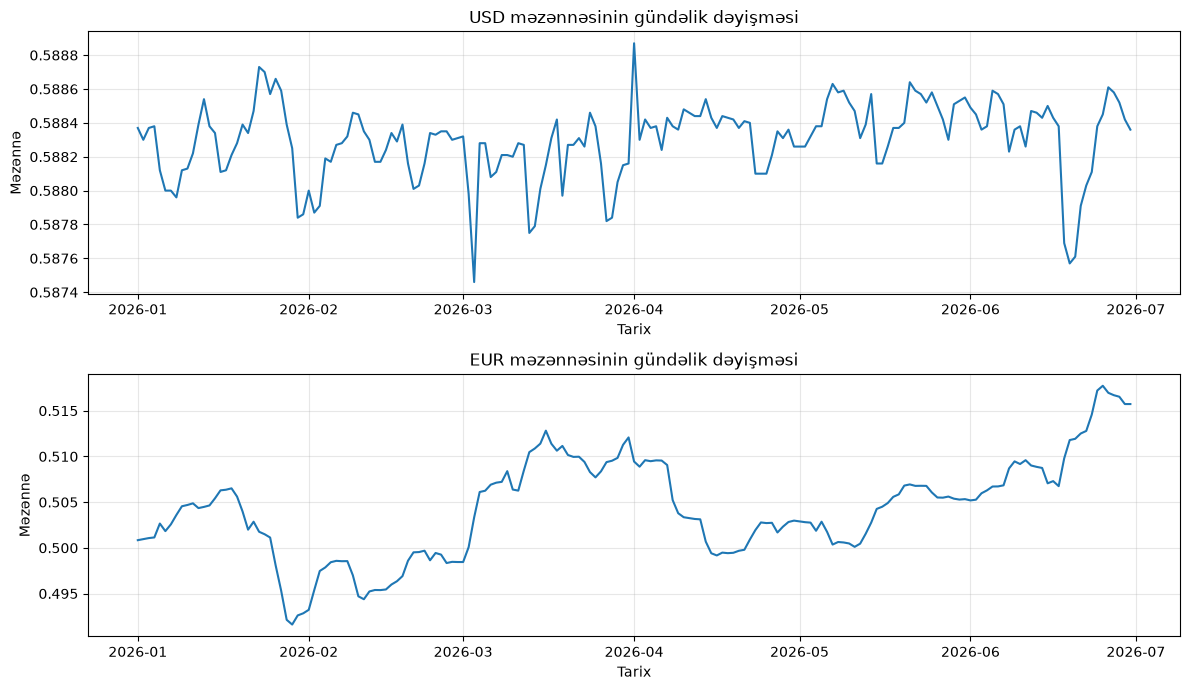

In [56]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

for ax, valyuta in zip(axes, ["usd", "eur"]):
    data = exchange_df[exchange_df["currency"] == valyuta]

    ax.plot(data["date"], data["mezenne"])
    ax.set_title(f"{valyuta.upper()} məzənnəsinin gündəlik dəyişməsi")
    ax.set_xlabel("Tarix")
    ax.set_ylabel("Məzənnə")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 2026-cı ilin yanvar–iyun aylarında USD məzənnəsi əsasən sabit qalmış, yalnız kiçik gündəlik dalğalanmalar göstərmişdir.

### EUR məzənnəsində isə daha nəzərəçarpan dəyişikliklər müşahidə edilmişdir. Yanvarın sonunda azalma, mart ayında yüksəliş, apreldə yenidən azalma və iyunun sonunda artım qeydə alınmışdır.

In [57]:
for valyuta in ["usd", "eur"]:
    data = exchange_df[exchange_df["currency"] == valyuta]

    print(f"\n{valyuta.upper()} üzrə korrelyasiya:")

    for sutun in ["tranzaksiya_sayi", "umumi_mebleg"]:
        r = data["mezenne"].corr(data[sutun])

        print(f"{sutun}: r = {r:.3f}")


USD üzrə korrelyasiya:
tranzaksiya_sayi: r = -0.039
umumi_mebleg: r = -0.063

EUR üzrə korrelyasiya:
tranzaksiya_sayi: r = -0.085
umumi_mebleg: r = -0.083


r > 0: Müsbət əlaqə

r < 0: Mənfi əlaqə

r ≈ 0: Xətti əlaqə zəifdir və ya yoxdur


#### Bütün korrelyasiya əmsalları 0-a çox yaxındır. Bu isə güclü xətti əlaqənin müşahidə edilmədiyini göstərir. Araşdırılan dövrdə USD və EUR məzənnələrinin səviyyəsi ilə gündəlik tranzaksiya aktivliyi arasında nəzərəçarpan xətti əlaqə aşkar edilməmişdir. 

## Korrelyasiya üzrə hipotez testi

Məzənnə ilə gündəlik tranzaksiya sayı və məbləği arasındakı xətti əlaqənin statistik əhəmiyyətini yoxlamaq.

#### H₀: Məzənnə ilə tranzaksiya göstəriciləri arasında xətti korrelyasiya yoxdur.

#### H₁: Məzənnə ilə tranzaksiya göstəriciləri arasında xətti korrelyasiya var.

#### Pearson testi seçək Pearson testi məzənnə ilə tranzaksiya sayı və məbləği kimi ədədi göstəricilər arasındakı xətti əlaqənin gücünü, istiqamətini və statistik əhəmiyyətini yoxlamaq üçün seçilmişdir.

In [58]:
from scipy.stats import pearsonr

for valyuta in ["usd", "eur"]:
    data = exchange_df[exchange_df["currency"] == valyuta]

    print(f"\n{valyuta.upper()} üzrə hipotez testi:")

    for sutun in ["tranzaksiya_sayi", "umumi_mebleg"]:
        r, p = pearsonr(data["mezenne"], data[sutun])

        print(f"\nGöstərici: {sutun}")
        print(f"Korrelyasiya (r): {r:.3f}")
        print(f"P-dəyəri: {p:.4f}")

        if p < 0.05:
            print("Nəticə: Statistik əhəmiyyətli əlaqə var.")
        else:
            print("Nəticə: Statistik əhəmiyyətli əlaqə aşkar edilmədi.")


USD üzrə hipotez testi:

Göstərici: tranzaksiya_sayi
Korrelyasiya (r): -0.039
P-dəyəri: 0.6027
Nəticə: Statistik əhəmiyyətli əlaqə aşkar edilmədi.

Göstərici: umumi_mebleg
Korrelyasiya (r): -0.063
P-dəyəri: 0.3999
Nəticə: Statistik əhəmiyyətli əlaqə aşkar edilmədi.

EUR üzrə hipotez testi:

Göstərici: tranzaksiya_sayi
Korrelyasiya (r): -0.085
P-dəyəri: 0.2529
Nəticə: Statistik əhəmiyyətli əlaqə aşkar edilmədi.

Göstərici: umumi_mebleg
Korrelyasiya (r): -0.083
P-dəyəri: 0.2684
Nəticə: Statistik əhəmiyyətli əlaqə aşkar edilmədi.


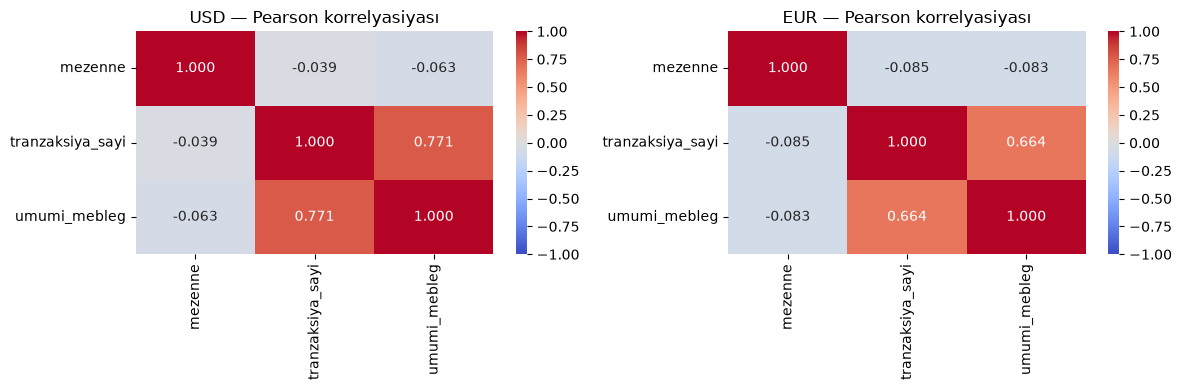

In [59]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, valyuta in zip(axes, ["usd", "eur"]):
    data = exchange_df[exchange_df["currency"] == valyuta]

    corr = data[
        ["mezenne", "tranzaksiya_sayi", "umumi_mebleg"]
    ].corr(method="pearson")

    sns.heatmap(
        corr,
        annot=True,
        fmt=".3f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        ax=ax
    )

    ax.set_title(f"{valyuta.upper()} — Pearson korrelyasiyası")

plt.tight_layout()
plt.show()

### Pearson korrelyasiya istilik xəritəsinə əsasən, USD və EUR məzənnələri ilə gündəlik tranzaksiya sayı və məbləği arasında çox zəif mənfi əlaqə müşahidə edilmişdir.

 ## Hava temperaturunun statistik təhlili
 #### Hava temperaturu ilə gündəlik tranzaksiya sayı və məbləği arasındakı əlaqəni araşdıraq

In [3]:
weather_df = pd.read_sql_table("transactions", engine, schema="silver")

weather_df["date"] = pd.to_datetime(weather_df["date"])

temp_df = weather_df.groupby(
    ["date", "city"]
).agg(
    temperatur=("temperature_2m_mean", "mean"),
    tranzaksiya_sayi=("transaction_id", "count")
   ).reset_index()

display(temp_df.head(10))
print("Cədvəlin ölçüsü:", temp_df.shape)

,date,city,temperatur,tranzaksiya_sayi
0,2026-01-01,bakı,4.1,362
1,2026-01-01,gəncə,3.5,76
2,2026-01-01,lənkəran,7.2,40
3,2026-01-01,mingəçevir,5.5,35
4,2026-01-01,naxçıvan,0.8,24
5,2026-01-01,sumqayıt,4.1,55
6,2026-01-01,şəki,1.8,31
7,2026-01-02,bakı,2.9,401
8,2026-01-02,gəncə,2.0,107
9,2026-01-02,lənkəran,5.2,45


Cədvəlin ölçüsü: (1267, 4)


In [4]:
print("Sətir sayı:", len(temp_df))
print("Şəhər sayı:", temp_df["city"].nunique())

print("\nBoş dəyərlər:")
print(temp_df.isnull().sum())

print("\nTəkrarlanan tarix-şəhər:")
print(temp_df.duplicated(["date", "city"]).sum())

print("\nTemperatur aralığı:")
print("Minimum:", temp_df["temperatur"].min())
print("Maksimum:", temp_df["temperatur"].max())

Sətir sayı: 1267
Şəhər sayı: 7

Boş dəyərlər:
date                0
city                0
temperatur          0
tranzaksiya_sayi    0
dtype: int64

Təkrarlanan tarix-şəhər:
0

Temperatur aralığı:
Minimum: -6.0
Maksimum: 30.4


### Temperaturun təsviri statistikası. Temperaturun paylanmasını, orta qiymətini və şəhərlər üzrə fərqlərini araşdıraq

In [ ]:
display(temp_df["temperatur"].describe().round(2))

seher_temp = temp_df.groupby("city")["temperatur"].agg(
    ["mean", "min", "max"]
).round(2)

display(seher_temp)

Temperaturun təsviri statistikası:


count    1267.00
mean       12.09
std         7.39
min        -6.00
25%         6.30
50%        11.60
75%        18.00
max        30.40
Name: temperatur, dtype: float64

,mean,min,max
city,,,
bakı,12.41,0.2,28.4
gəncə,11.69,-1.7,27.8
lənkəran,13.44,-0.7,27.2
mingəçevir,13.42,0.7,29.8
naxçıvan,10.97,-5.4,30.4
sumqayıt,12.47,0.0,27.8
şəki,10.25,-6.0,26.3


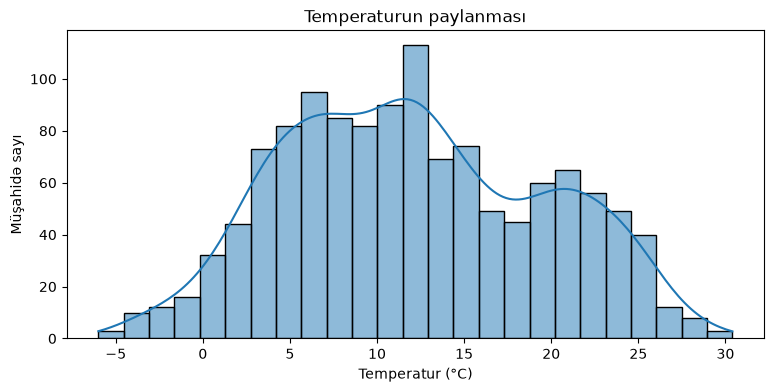

In [6]:
plt.figure(figsize=(9, 4))

sns.histplot(temp_df["temperatur"], bins=25, kde=True)

plt.title("Temperaturun paylanması")
plt.xlabel("Temperatur (°C)")
plt.ylabel("Müşahidə sayı")

plt.show()

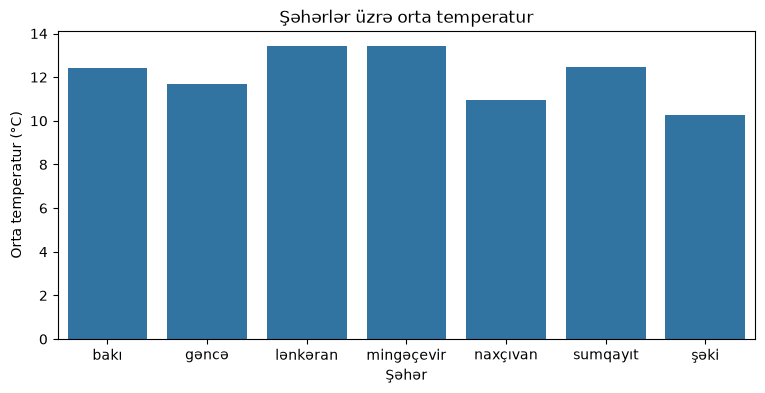

In [7]:
plt.figure(figsize=(9, 4))

sns.barplot(data=temp_df, x="city", y="temperatur", errorbar=None)

plt.title("Şəhərlər üzrə orta temperatur")
plt.xlabel("Şəhər")
plt.ylabel("Orta temperatur (°C)")

plt.show()

1267 müşahidə üzrə orta temperatur 12.09°C, median 11.60°C, standart kənarlaşma isə 7.39°C olmuşdur. Temperatur −6.0°C ilə 30.4°C arasında dəyişmişdir.

Şəhərlər arasında ən yüksək orta temperatur Lənkəranda (13.44°C), ən aşağı isə Şəkidə (10.25°C) müşahidə edilmişdir.

### Temperatur və tranzaksiya sayı arasında korrelyasiya

Hava temperaturu ilə gündəlik tranzaksiya sayı arasındakı xətti əlaqənin gücünü müəyyən etmək.

Şəhərlərdə tranzaksiya həcmləri fərqli olduğuna görə Pearson korrelyasiyası hər şəhər üçün ayrıca hesablanır.

Şəhərlərdə müştəri və tranzaksiya sayı fərqli olduğundan, bütün məlumatların birlikdə müqayisəsi yanlış əlaqə yarada bilər.

Buna görə temperatur ilə tranzaksiya sayı arasındakı korrelyasiya hər şəhər daxilində ayrıca hesablanır. Bu yanaşma şəhərlər arasındakı tranzaksiya həcmi fərqlərinin nəticəyə təsirini azaltmağa kömək edir.

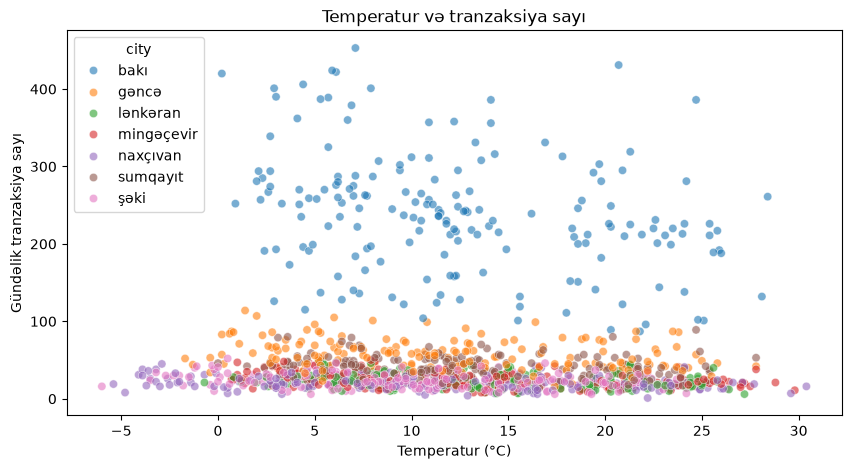

In [8]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=temp_df,
    x="temperatur",
    y="tranzaksiya_sayi",
    hue="city",
    alpha=0.6
)

plt.title("Temperatur və tranzaksiya sayı")
plt.xlabel("Temperatur (°C)")
plt.ylabel("Gündəlik tranzaksiya sayı")
plt.show()

In [9]:
from scipy.stats import pearsonr

neticeler = []

for seher, data in temp_df.groupby("city"):
    r, p = pearsonr(data["temperatur"], data["tranzaksiya_sayi"])

    neticeler.append({
        "Şəhər": seher,
        "Korrelyasiya (r)": round(r, 3),
        "P-dəyəri": round(p, 4)
    })

corr_df = pd.DataFrame(neticeler)

display(corr_df)

,Şəhər,Korrelyasiya (r),P-dəyəri
0,bakı,-0.293,0.0001
1,gəncə,-0.256,0.0005
2,lənkəran,-0.251,0.0007
3,mingəçevir,-0.336,0.0000
4,naxçıvan,-0.266,0.0003
5,sumqayıt,-0.132,0.0770
6,şəki,-0.288,0.0001


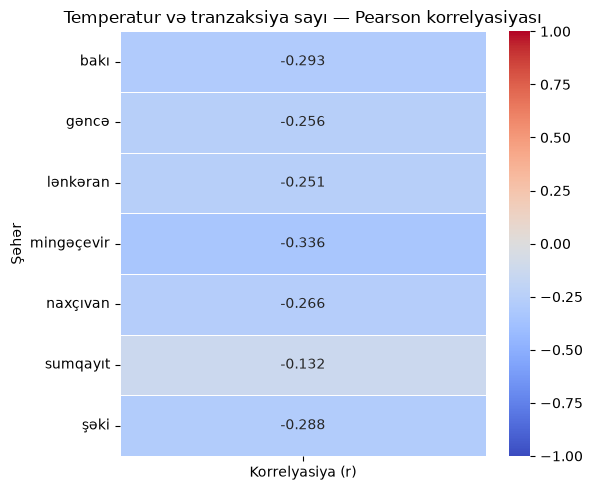

In [10]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    corr_df.set_index("Şəhər")[["Korrelyasiya (r)"]],
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Temperatur və tranzaksiya sayı — Pearson korrelyasiyası")
plt.xlabel("")
plt.ylabel("Şəhər")

plt.tight_layout()
plt.show()